# Korelacje pod predykcję goli, rzutów karnych i wyniku meczu

Ten notatnik w prosty sposób sprawdza, które kolumny najmocniej wiążą się z:
1. **Golami (`is_goal`)** oraz **stuprocentowymi sytuacjami (`is_big_chance`)**,
2. **Rzutami karnymi (`is_penalty`)**,
3. **Wynikiem meczu (`gole_suma`)** oraz **oceną zawodnika (`final_rating`)**.


## 1. Wczytanie danych i dodanie prostych cech boiskowych
Wczytujemy tabele `events` i `players`, łączymy je po `player_id` i dodajemy kilka prostych kolumn `0/1` (np. czy akcja była w polu karnym, odległość od bramki, czy był to faul w polu karnym).


In [12]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "output"
FIGURY = DATA / "figures"
FIGURY.mkdir(parents=True, exist_ok=True)

MATCH = "match_1821123_Southampton_vs_Aston_Villa"

events = pd.read_csv(DATA / f"{MATCH}_events.csv")
players = pd.read_csv(DATA / f"{MATCH}_players.csv")

# 1. Doklejamy wzrost, wagę i ocenę końcową zawodnika z tabeli players
events = events.merge(
    players[["player_id", "height_cm", "weight_kg", "final_rating"]],
    on="player_id",
    how="left",
)

# 2. Zamieniamy kolumny True/False na liczby 1/0 (żeby liczyć korelacje)
kolumny_bool = ["is_goal", "is_shot", "is_big_chance", "is_penalty", "is_key_pass", "is_through_ball", "is_cross", "is_long_ball", "is_first_touch"]
for kol in kolumny_bool:
    events[kol] = events[kol].fillna(False).astype(int)

# 3. Tworzymy proste, zrozumiałe cechy pod gole i karne:
# Środek bramki przeciwnika to punkt (x=100, y=50)
events["dystans_do_bramki"] = np.sqrt((100 - events["x"]) ** 2 + (50 - events["y"]) ** 2)

# Pole karne: x >= 83 (atak) lub x <= 17 (obrona), szerokość y od 21 do 79
events["w_polu_karnym"] = ((events["x"] >= 83) & (events["y"].between(21, 79))).astype(int)
w_polu_karnym_obrona = ((events["x"] <= 17) & (events["y"].between(21, 79))).astype(int)

# Środek pola karnego przed samą bramką (tzw. złota strefa: x >= 88, y od 36 do 64)
events["zlota_strefa"] = ((events["x"] >= 88) & (events["y"].between(36, 64))).astype(int)

# Celny strzał oraz faul w polu karnym
events["strzal_celny"] = events["event_type"].isin(["Goal", "SavedShot"]).astype(int)
events["czy_faul"] = (events["event_type"] == "Foul").astype(int)
events["faul_w_polu_karnym"] = (events["czy_faul"] & (events["w_polu_karnym"] | w_polu_karnym_obrona)).astype(int)

# Czy chwilę wcześniej (w poprzednim wierszu) było kluczowe lub prostopadłe podanie?
events["po_kluczowym_podaniu"] = events["is_key_pass"].shift(1, fill_value=0)
events["po_podaniu_prostopadlym"] = events["is_through_ball"].shift(1, fill_value=0)

print("Liczba wszystkich zdarzeń :", len(events))
print("Liczba oddanych strzałów  :", events["is_shot"].sum())
print("Liczba zdobytych goli     :", events["is_goal"].sum())
print("Zdarzenia rzutów karnych  :", events["is_penalty"].sum())


Liczba wszystkich zdarzeń : 1468
Liczba oddanych strzałów  : 32
Liczba zdobytych goli     : 3
Zdarzenia rzutów karnych  : 10


## 2. Korelacje z Golem, Stuprocentową szansą, Strzałem i Rzutem karnym
Używamy zwykłej metody `.corr()` z biblioteki Pandas. Sprawdzamy 3 standardowe miary:
- **`pearson`** — klasyczna korelacja liniowa,
- **`spearman`** — korelacja rangowa (monotoniczna, jak w `02_eda_events.ipynb`),
- **`kendall`** — korelacja porządkowa.


In [13]:
wybrane_kolumny = [
    "is_goal",
    "is_big_chance",
    "strzal_celny",
    "is_shot",
    "is_penalty",
    "faul_w_polu_karnym",
    "czy_faul",
    "zlota_strefa",
    "w_polu_karnym",
    "dystans_do_bramki",
    "is_first_touch",
    "po_kluczowym_podaniu",
    "po_podaniu_prostopadlym",
    "x",
    "y",
]

# Liczymy 3 rodzaje korelacji wbudowaną funkcją Pandas
kor_pearson = events[wybrane_kolumny].corr(method="pearson")
kor_spearman = events[wybrane_kolumny].corr(method="spearman")
kor_kendall = events[wybrane_kolumny].corr(method="kendall")

# Zestawienie dla GOLI (is_goal)
tabela_gole = pd.DataFrame({
    "pearson": kor_pearson["is_goal"],
    "spearman": kor_spearman["is_goal"],
    "kendall": kor_kendall["is_goal"],
}).drop("is_goal").sort_values("pearson", ascending=False)

print("=== CO NAJMOCNIEJ KORELUJE Z GOLEM (is_goal)? ===")
print(tabela_gole.head(8).round(3))

# Zestawienie dla RZUTÓW KARNYCH (is_penalty)
tabela_karne = pd.DataFrame({
    "pearson": kor_pearson["is_penalty"],
    "spearman": kor_spearman["is_penalty"],
    "kendall": kor_kendall["is_penalty"],
}).drop("is_penalty").sort_values("pearson", ascending=False)

print("\n=== CO NAJMOCNIEJ KORELUJE Z RZUTEM KARNYM (is_penalty)? ===")
print(tabela_karne.head(5).round(3))


=== CO NAJMOCNIEJ KORELUJE Z GOLEM (is_goal)? ===
                         pearson  spearman  kendall
is_big_chance              0.654     0.654    0.654
strzal_celny               0.395     0.395    0.395
zlota_strefa               0.351     0.351    0.351
po_podaniu_prostopadlym    0.332     0.332    0.332
is_shot                    0.303     0.303    0.303
is_first_touch             0.277     0.277    0.277
po_kluczowym_podaniu       0.243     0.243    0.243
w_polu_karnym              0.192     0.192    0.192

=== CO NAJMOCNIEJ KORELUJE Z RZUTEM KARNYM (is_penalty)? ===
                    pearson  spearman  kendall
faul_w_polu_karnym    0.514     0.514    0.514
is_big_chance         0.235     0.235    0.235
czy_faul              0.222     0.222    0.222
strzal_celny          0.137     0.137    0.137
w_polu_karnym         0.129     0.129    0.129


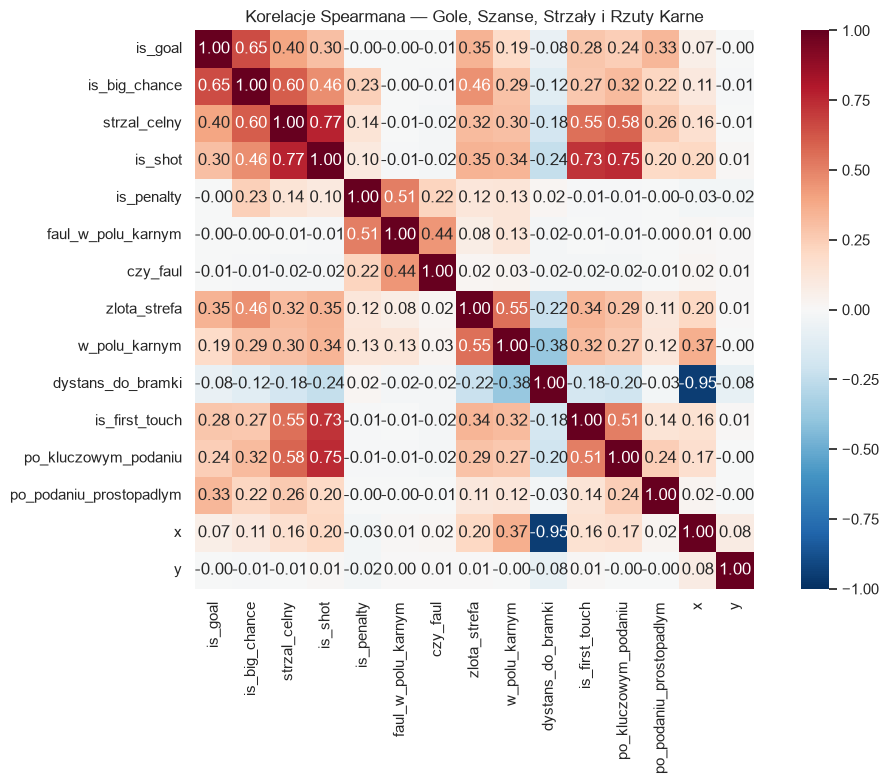

In [14]:
# Wykres macierzy korelacji
plt.figure(figsize=(11, 8))
sns.heatmap(kor_spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Korelacje Spearmana — Gole, Szanse, Strzały i Rzuty Karne")
plt.tight_layout()
plt.savefig(FIGURY / "03_korelacje_gole_karne.png", dpi=130)
plt.show()


## 3. Co decyduje o KOŃCOWYM WYNIKU meczu (liczbie strzelonych goli)?
Grupujemy zdarzenia minuta po minucie dla każdej drużyny i liczymy sumę narastającą (`.cumsum()`), aby zobaczyć, jakie statystyki prowadzą do zdobywania bramek w meczu.


In [17]:
# Zliczamy statystyki każdej drużyny w kolejnych minutach meczu
minutowe = (
    events.groupby(["team_name", "expanded_minute"])
    .agg(
        gole=("is_goal", "sum"),
        setki=("is_big_chance", "sum"),
        celne_strzaly=("strzal_celny", "sum"),
        strzaly=("is_shot", "sum"),
        wejscia_w_pole=("w_polu_karnym", "sum"),
        kluczowe_podania=("is_key_pass", "sum"),
        karne=("is_penalty", "sum"),
    )
    .reset_index()
)

# Liczymy sumę od początku meczu (.cumsum()) dla każdej drużyny
stat_kol = ["gole", "setki", "celne_strzaly", "strzaly", "wejscia_w_pole", "kluczowe_podania", "karne"]
for kol in stat_kol:
    minutowe[f"{kol}_suma"] = minutowe.groupby("team_name")[kol].cumsum()

kolumny_suma = [f"{k}_suma" for k in stat_kol]
korelacje_wynik = minutowe[kolumny_suma].corr(method="pearson")["gole_suma"].drop("gole_suma").sort_values(ascending=False)

print("=== KORELACJE ZE ZDOBYTYMI GOLAMI DRUŻYNY W MECZU (gole_suma) ===")
print(korelacje_wynik.round(3).to_string())


=== KORELACJE ZE ZDOBYTYMI GOLAMI DRUŻYNY W MECZU (gole_suma) ===
setki_suma               0.938
celne_strzaly_suma       0.747
strzaly_suma             0.701
wejscia_w_pole_suma      0.685
kluczowe_podania_suma    0.650
karne_suma               0.433


## 4. Ranking TOP 10 par i TOP 10 trójek (`cel ~ x1 + x2`) do trenowania modelu
Dokładnie ta sama funkca `r2_plaszczyzny(dane, x1, x2, y)` co w notatniku `02_eda_events.ipynb`, ale szukamy trójek przewidujących **gole, groźne strzały, rzuty karne i wynik meczu**.


In [16]:
# 1. Najlepsze PARY wśród kolumn meczowych
pary = []
for a, b in itertools.combinations(wybrane_kolumny, 2):
    pary.append((a, b, kor_pearson.loc[a, b]))
pary.sort(key=lambda t: -abs(t[2]))

print("=== TOP 10 PAR DO MODELU (Gole, Szanse, Karne, Strzały) ===")
for a, b, r in pary[:10]:
    print(f"  {a:<24} <-> {b:<24} r = {r:+.3f}")


# 2. Funkcja R² płaszczyzny najmniejszych kwadratów
def r2_plaszczyzny(dane, x1, x2, y):
    X = np.column_stack([np.ones(len(dane)), dane[x1], dane[x2]])
    y_prawdziwe = dane[y].to_numpy()
    beta, *_ = np.linalg.lstsq(X, y_prawdziwe, rcond=None)
    y_pred = X @ beta
    ss_res = ((y_prawdziwe - y_pred) ** 2).sum()
    ss_tot = ((y_prawdziwe - y_prawdziwe.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot


# Sprawdzamy trójki przewidujące gole (is_goal), szanse (is_big_chance), karne (is_penalty) i strzały (is_shot)
cele = ["is_goal", "is_big_chance", "is_penalty", "is_shot"]
cechy = [k for k in wybrane_kolumny if k not in ["x", "y"]]

trojki = []
for cel in cele:
    pozostale = [k for k in cechy if k != cel]
    for x1, x2 in itertools.combinations(pozostale, 2):
        dane = events[[x1, x2, cel]].dropna()
        r2 = r2_plaszczyzny(dane, x1, x2, cel)
        trojki.append((r2, cel, x1, x2))

# Dodajemy też trójki dla sumy goli w meczu (gole_suma)
for x1, x2 in itertools.combinations([k for k in kolumny_suma if k != "gole_suma"], 2):
    r2 = r2_plaszczyzny(minutowe, x1, x2, "gole_suma")
    trojki.append((r2, "gole_suma", x1, x2))

trojki.sort(key=lambda t: -t[0])

print("\n=== TOP 10 TRÓJEK (cel ~ x1 + x2) DLA GOLI, KARNYCH I WYNIKU ===")
for r2, cel, x1, x2 in trojki[:10]:
    print(f"  {cel:<24} ~ {x1:<22} + {x2:<22} R2 = {r2:.4f}")


=== TOP 10 PAR DO MODELU (Gole, Szanse, Karne, Strzały) ===
  dystans_do_bramki        <-> x                        r = -0.945
  strzal_celny             <-> is_shot                  r = +0.767
  is_shot                  <-> po_kluczowym_podaniu     r = +0.749
  is_shot                  <-> is_first_touch           r = +0.725
  is_goal                  <-> is_big_chance            r = +0.654
  is_big_chance            <-> strzal_celny             r = +0.604
  strzal_celny             <-> po_kluczowym_podaniu     r = +0.581
  strzal_celny             <-> is_first_touch           r = +0.551
  zlota_strefa             <-> w_polu_karnym            r = +0.548
  is_penalty               <-> faul_w_polu_karnym       r = +0.514

=== TOP 10 TRÓJEK (cel ~ x1 + x2) DLA GOLI, KARNYCH I WYNIKU ===
  gole_suma                ~ setki_suma             + kluczowe_podania_suma  R2 = 0.8840
  gole_suma                ~ setki_suma             + strzaly_suma           R2 = 0.8827
  gole_suma               